In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("cars_2010_2020.csv")

In [6]:
df.head()

,Make,Model,Year,Engine Size (L),Fuel Type,Price (USD)
0,Volkswagen,Jetta,2010,4.2,Petrol,54073.09
1,Honda,Pilot,2017,4.2,Hybrid,44924.91
2,Nissan,Murano,2011,4.2,Hybrid,76963.44
3,Toyota,RAV4,2010,2.4,Petrol,30871.25
4,Nissan,Altima,2010,3.6,Petrol,72037.65


In [8]:
df.shape

(10000, 6)

In [9]:
df.columns

Index(['Make', 'Model', 'Year', 'Engine Size (L)', 'Fuel Type', 'Price (USD)'], dtype='object')

In [10]:
df.columns.tolist()

['Make', 'Model', 'Year', 'Engine Size (L)', 'Fuel Type', 'Price (USD)']

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Make             10000 non-null  object 
 1   Model            10000 non-null  object 
 2   Year             10000 non-null  int64  
 3   Engine Size (L)  10000 non-null  float64
 4   Fuel Type        10000 non-null  object 
 5   Price (USD)      10000 non-null  float64
dtypes: float64(2), int64(1), object(3)
memory usage: 468.9+ KB


In [12]:
print(df.select_dtypes(include="number").columns.tolist())

['Year', 'Engine Size (L)', 'Price (USD)']


In [13]:
print(df.select_dtypes(include="object").columns.tolist())

['Make', 'Model', 'Fuel Type']


In [14]:
print(df.isnull().sum())

Make               0
Model              0
Year               0
Engine Size (L)    0
Fuel Type          0
Price (USD)        0
dtype: int64


In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df = df.drop_duplicates().copy()

In [17]:
# Remove unnecessary spaces from text values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()


In [18]:
df.describe()

,Year,Engine Size (L),Price (USD)
count,10000.000000,10000.000000,10000.000000
mean,2014.969900,2.992240,47397.584981
std,3.174303,1.150697,18643.431581
min,2010.000000,1.000000,15010.250000
25%,2012.000000,2.000000,31214.385000
50%,2015.000000,3.000000,47272.105000
75%,2018.000000,4.000000,63325.882500
max,2020.000000,5.000000,79998.870000


In [19]:
df.describe(include="object")

,Make,Model,Fuel Type
count,10000,10000,10000
unique,10,50,4
top,Nissan,Sentra,Hybrid
freq,1032,226,2539


In [20]:
df.nunique()

,0
Make,10
Model,50
Year,11
Engine Size (L),41
Fuel Type,4
Price (USD),9985


In [21]:
df.columns.tolist()

['Make', 'Model', 'Year', 'Engine Size (L)', 'Fuel Type', 'Price (USD)']

In [22]:
price_col = next(
    (col for col in df.columns if "price" in col.lower()),
    None
)
print(price_col)

Price (USD)


In [23]:
if price_col is None:
    print("No price column found. Check the dataset.")
else:
  print("Mean: ", df[price_col].mean())
  print("Median: ", df[price_col].median())
  print("Mode: ", df[price_col].mode())

Mean:  47397.584981
Median:  47272.104999999996
Mode:  0     19747.50
1     20163.37
2     20890.91
3     22274.34
4     26203.56
5     30351.97
6     37796.57
7     44584.79
8     44631.58
9     51441.50
10    56299.36
11    59272.62
12    69784.41
13    70307.34
14    74507.15
Name: Price (USD), dtype: float64


In [24]:
df["Make"].value_counts().head(10)

,count
Make,
Nissan,1032
Volkswagen,1029
Chevrolet,1025
Audi,1019
Hyundai,1011
Honda,989
BMW,986
Ford,975
Mercedes-Benz,973


In [25]:
df["Fuel Type"].value_counts()

,count
Fuel Type,
Hybrid,2539
Diesel,2528
Electric,2485
Petrol,2448


In [26]:
sns.set_theme(style="whitegrid")

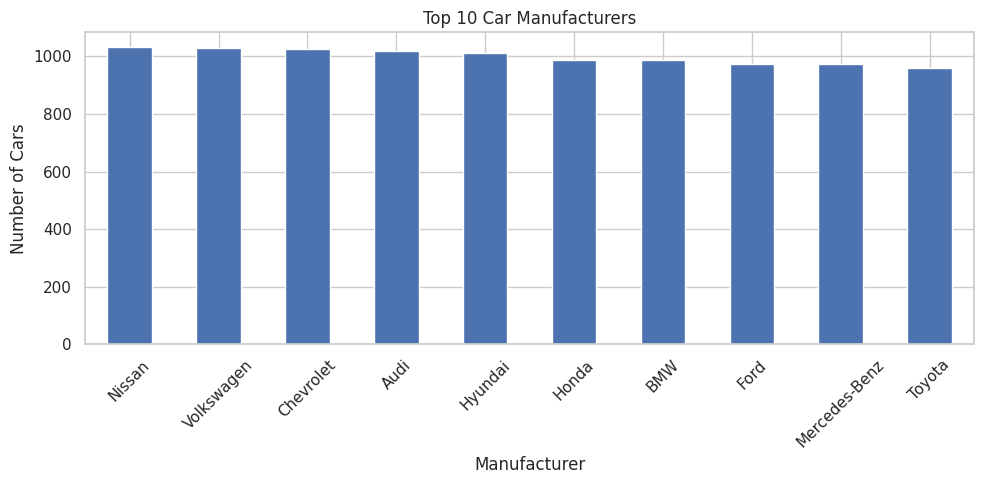

In [27]:
# Chart 1: Top 10 manufacturers
plt.figure(figsize=(10, 5))
df["Make"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 Car Manufacturers")
plt.xlabel("Manufacturer")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

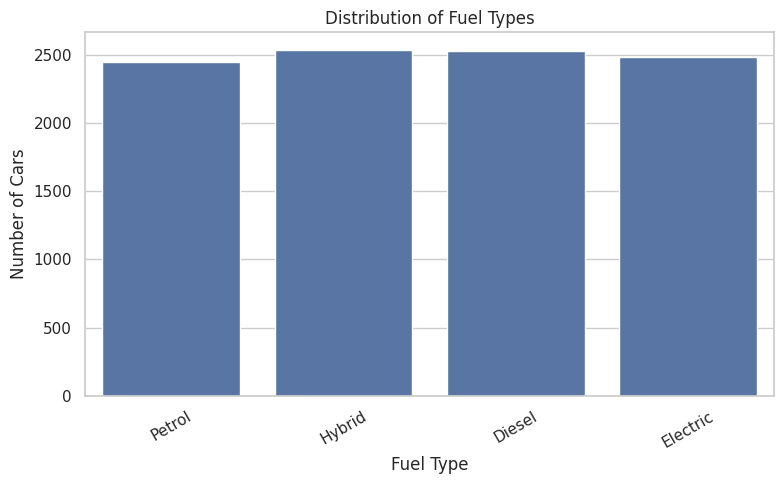

In [28]:
# Chart 2: Fuel type distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Fuel Type")
plt.title("Distribution of Fuel Types")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

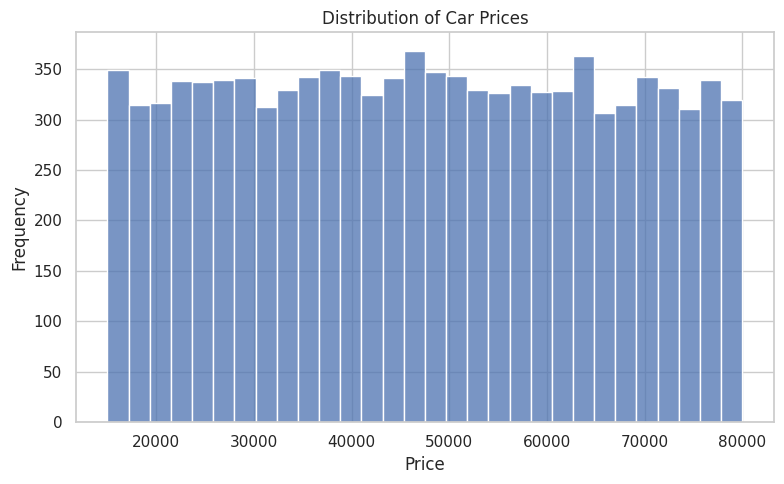

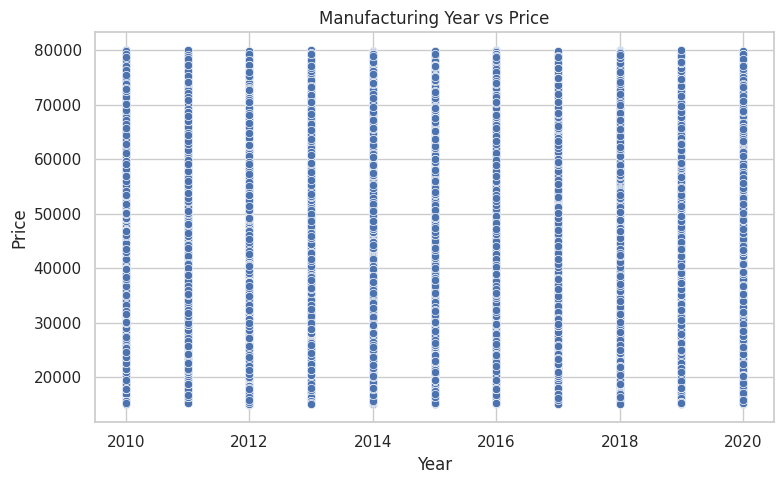

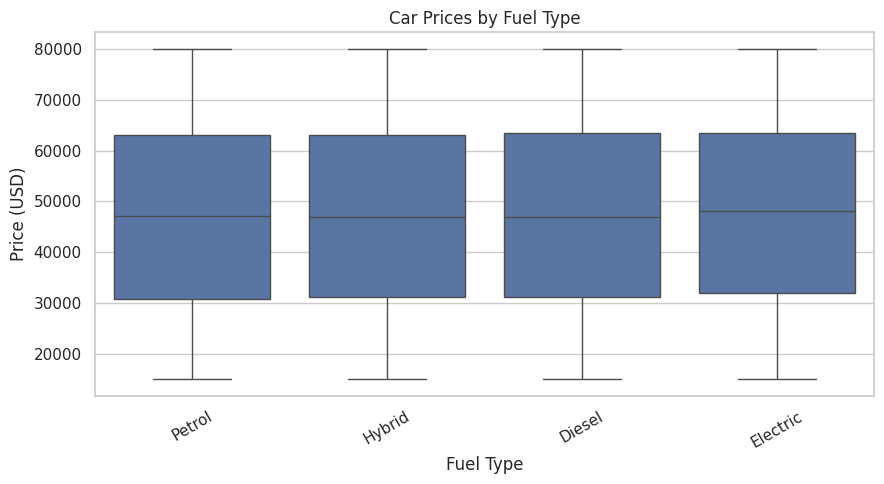

In [29]:
if price_col is not None:
  # Chart 3: Price distribution
    plt.figure(figsize=(8, 5))
    sns.histplot(df[price_col].dropna(), bins=30)
    plt.title("Distribution of Car Prices")
    plt.xlabel("Price")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

  # Chart 4: Year versus price
    plt.figure(figsize=(8, 5))
    sns.scatterplot(data=df, x="Year", y=price_col)
    plt.title("Manufacturing Year vs Price")
    plt.xlabel("Year")
    plt.ylabel("Price")
    plt.tight_layout()
    plt.show()

  # Chart 5: Price by fuel type
    plt.figure(figsize=(9, 5))
    sns.boxplot(data=df, x="Fuel Type", y=price_col)
    plt.title("Car Prices by Fuel Type")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()



<Axes: >

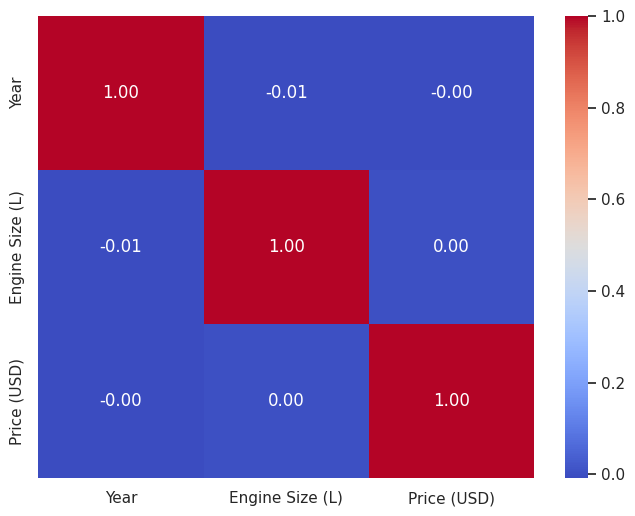

In [30]:
# Chart 6: Correlation heatmap
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(8, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

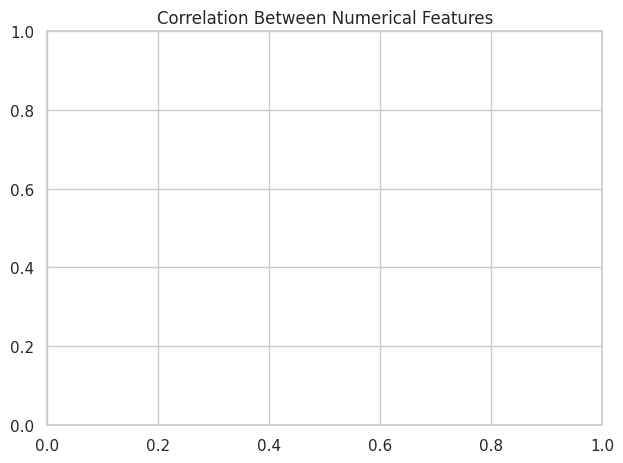

In [31]:
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [32]:
df["Make"].value_counts().head(1)

,count
Make,
Nissan,1032


In [33]:
df["Fuel Type"].value_counts().head(1)

,count
Fuel Type,
Hybrid,2539


In [34]:
df["Year"].value_counts().sort_index()

,count
Year,
2010,962
2011,927
2012,861
2013,911
2014,890
2015,963
2016,877
2017,895
2018,907


In [35]:
if price_col is not None:
    print("\n4. Average price by manufacturer:")
    print(
        df.groupby("Make")[price_col]
        .mean()
        .sort_values(ascending=False)
        .head(10)
    )

    print("\n5. Average price by fuel type:")
    print(
        df.groupby("Fuel Type")[price_col]
        .mean()
        .sort_values(ascending=False)
    )



4. Average price by manufacturer:
Make
Volkswagen       48047.993955
Mercedes-Benz    47984.364810
Nissan           47943.220320
Chevrolet        47736.445746
Honda            47424.814671
BMW              47351.470456
Ford             47021.226482
Audi             46980.565289
Hyundai          46881.563640
Toyota           46545.861124
Name: Price (USD), dtype: float64

5. Average price by fuel type:
Fuel Type
Electric    47747.165449
Diesel      47537.206242
Hybrid      47196.415364
Petrol      47107.184510
Name: Price (USD), dtype: float64
